# Beyond the Normal: Using Skewness and Kurtosis to Model House Prices

## Aim

 This analysis aims to show that variation in house prices is not normally distributed, exhibiting heavy tails and a rightward skew that cannot be explained by anomalies or major qualitative differences.
Distributions, such as Azzalini skew-t, that parameterise skew and tailedness, are shown to far better explain house price variation, and the consequences of wrongly assuming normality are explored.

## Data

This data is a random selection of 1,460 of 2,930 houses sold in Ames, Iowa, from 2006 to 2010. It was compiled by De Cock (2011), who removed non-residential\* and repeat sales† from a set of 3,970 property sales recorded by local government. It serves as the basis for the *House Prices* Kaggle competition.

\* For example: garages, condos, storage areas.
† For houses with multiple sales recorded in the period, only the most recent was included.

First, we check for mistakes and anomalies:

1. Mistakes could be due to missing or duplicated data
2. Mistakes could be due to errors in the recorded price
3. Anomalies could be due to the 2008 financial crash occuring within the period
4. Anomalies could be due to abnormal situations, such as foreclosure, forcing a sale below market value


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train.csv")

print("Houses:", len(train))
print("Duplicate houses:", train.duplicated().sum())
print("Missing SalePrice:", train["SalePrice"].isna().sum())
print("Missing GrLivArea:", train["GrLivArea"].isna().sum())

Houses: 1460
Duplicated rows: 0
Duplicated Ids: 0
Missing SalePrice: 0
Missing GrLivArea: 0


In [ ]:

2. Mistakes could be due to errors in the recorded price

First we deal with obvious errors in recorded sale price. We will only consider ordinary sales, where unreasonable values can be put down to an error in recording. These are 'Normal' and 'Partial' sales (using SaleCondition classification), 'Partial' sales being the sale of a newbuild not yet completed.

To detect mistakes, we will see if any SalePrice (price paid for the property excluding taxes and commissions) is unreasonable, given the GnrLivArea (total 'above ground living area' ('above ground' meaning basements are excluded, 'living area' meaning porches and garages are excluded), we will refer to this as 'area') and age at sale of the house.
The price of a house should roughly scale with area, mediated by the age, which is shown by the colours of the data points (with red being newbuilds).


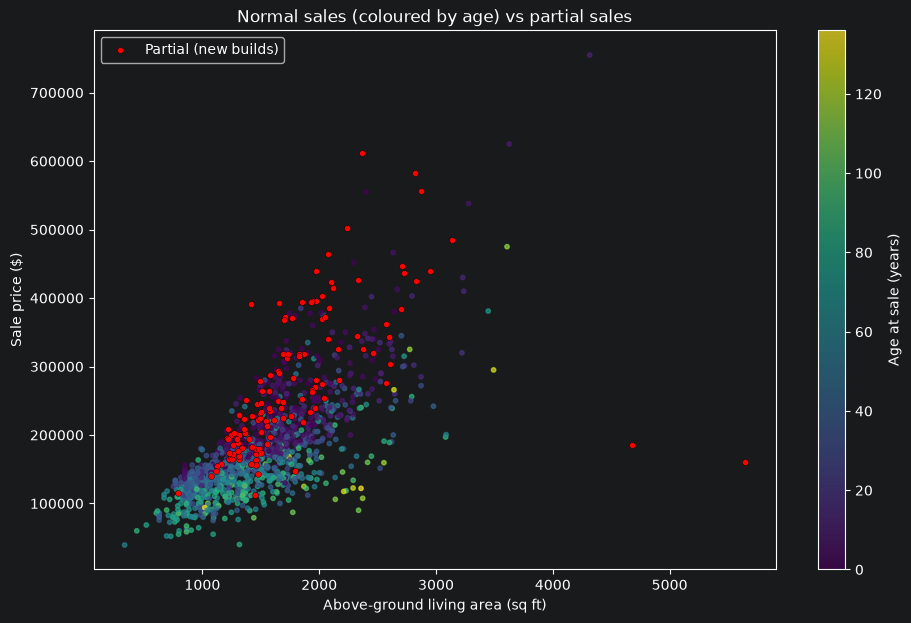

In [2]:
# Normal sales, with age at sale
normal = train[train["SaleCondition"] == "Normal"].copy()
normal["Age"] = normal["YrSold"] - normal["YearBuilt"]

# Partial sales (all of them, anomalies included)
partial = train[train["SaleCondition"] == "Partial"]

fig, ax = plt.subplots(figsize=(11, 7))
sc = ax.scatter(normal["GrLivArea"], normal["SalePrice"], c=normal["Age"],
                cmap="viridis", s=10, alpha=0.7)
fig.colorbar(sc, ax=ax, label="Age at sale (years)")
ax.scatter(partial["GrLivArea"], partial["SalePrice"], color="red", s=18,
           edgecolor="black", linewidth=0.3, label="Partial (new builds)")

ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Sale price ($)")
ax.set_title("Normal sales (coloured by age) vs partial sales")
ax.legend(loc="upper left")
plt.show()

In [ ]:

Here we see a clear correlation between size and price, especially when controlling for age, with two clear anomalies bucking the trend (red points on far right), which will be assumed to be errors. They are the largest houses, new, yet averagely priced. They will be removed.


In [ ]:

3. Outliers could be due to the 2008 financial crash occuring within the period


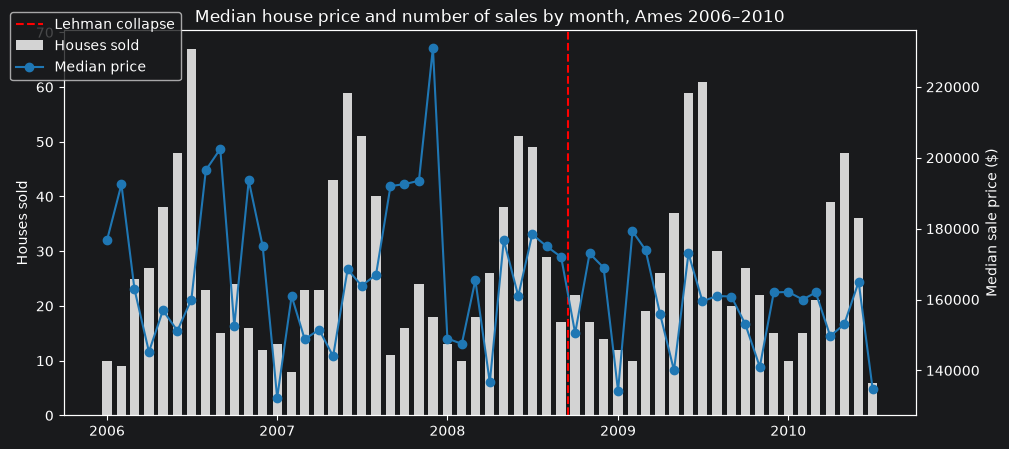

In [3]:
import matplotlib.pyplot as plt

monthly = (train.groupby(["YrSold", "MoSold"])["SalePrice"]
                .agg(median_price="median", houses_sold="count")
                .reset_index())
monthly["date"] = pd.to_datetime(dict(year=monthly["YrSold"], month=monthly["MoSold"], day=1))

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(monthly["date"], monthly["houses_sold"], width=20, color="lightgrey", label="Houses sold")
ax1.set_ylabel("Houses sold")

ax2 = ax1.twinx()
ax2.plot(monthly["date"], monthly["median_price"], color="tab:blue", marker="o", label="Median price")
ax2.set_ylabel("Median sale price ($)")

ax1.axvline(pd.Timestamp("2008-09-15"), color="red", linestyle="--", label="Lehman collapse")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.93))
ax1.set_title("Median house price and number of sales by month, Ames 2006–2010")
plt.show()

In [ ]:

This graph shows that the number of houses sold and median price was likely not meaningfully biased by the 2008 financial crisis. The post-crisis data is roughly on the same level, and exhibits the same cycles, as pre-crisis.


In [ ]:

4. Anomalies could be due to abnormal situations, such as foreclosure, forcing a sale below market value

Now we consider the non-ordinary SaleCondition classifications:
Abnorml: Any trade or situation where buyer or seller is under pressure (such as short sale or foreclosure)
Family: Buyer and seller related
AdjLand: Purchase of property adjacent to property owned by buyer
Alloca: Two seperate properties bought in one transaction, and price paid 'allocated' between the two


Excluded: [524, 1299]


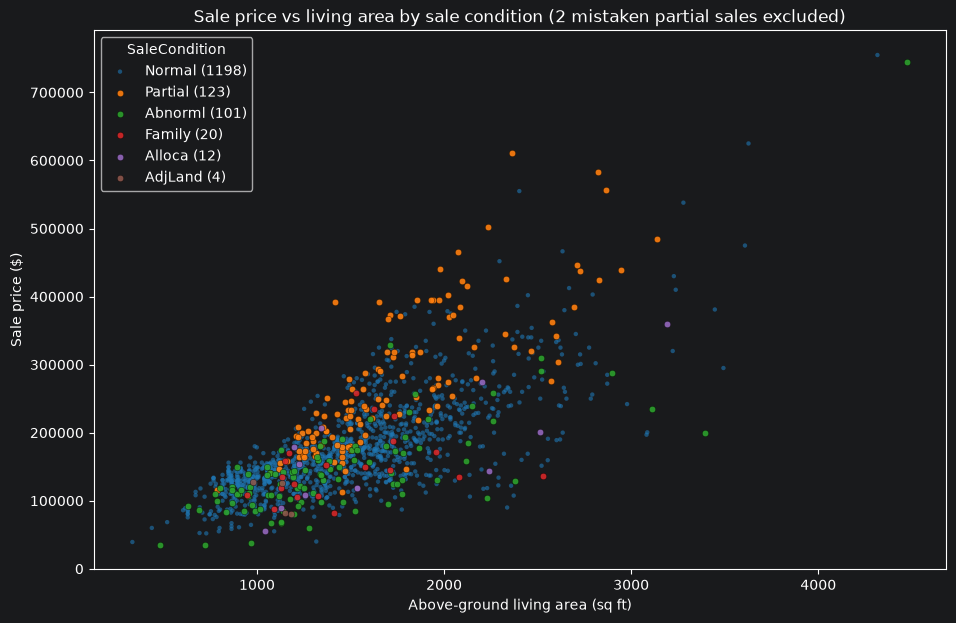

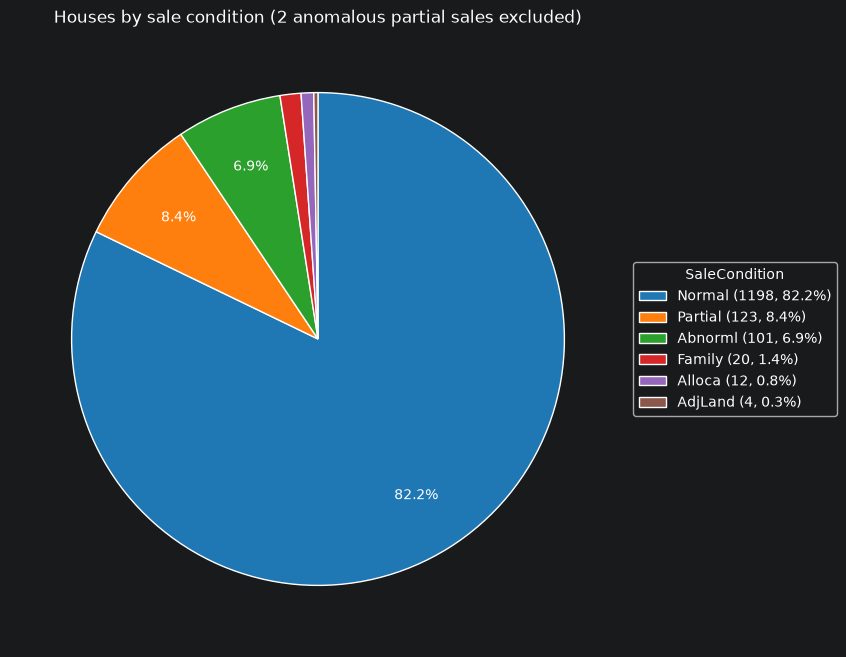

,Cheapest,2nd,3rd,4th
D1: 334–912 sq ft,"$34,900 · 720 sq ft · Id 496","$35,311 · 480 sq ft · Id 917","$39,300 · 334 sq ft · Id 534","$52,000 · 729 sq ft · Id 711"
"D2: 913–1,065 sq ft","$37,900 · 968 sq ft · Id 969","$55,993 · 1,044 sq ft · Id 813","$64,500 · 968 sq ft · Id 1433","$79,500 · 935 sq ft · Id 590"
"D3: 1,067–1,208 sq ft","$55,000 · 1,092 sq ft · Id 706","$66,500 · 1,131 sq ft · Id 875","$67,000 · 1,077 sq ft · Id 399","$68,400 · 1,128 sq ft · Id 1280"
"D4: 1,211–1,338 sq ft","$40,000 · 1,317 sq ft · Id 31","$60,000 · 1,276 sq ft · Id 411","$76,500 · 1,306 sq ft · Id 251","$87,000 · 1,248 sq ft · Id 1023"
"D5: 1,339–1,459 sq ft","$79,000 · 1,440 sq ft · Id 243","$82,500 · 1,411 sq ft · Id 633","$89,500 · 1,406 sq ft · Id 308","$91,500 · 1,456 sq ft · Id 1073"
"D6: 1,464–1,577 sq ft","$85,000 · 1,526 sq ft · Id 89","$98,000 · 1,529 sq ft · Id 750","$102,000 · 1,522 sq ft · Id 1010","$108,000 · 1,510 sq ft · Id 652"
"D7: 1,578–1,709 sq ft","$95,000 · 1,699 sq ft · Id 1187","$100,000 · 1,664 sq ft · Id 1012","$107,400 · 1,605 sq ft · Id 75","$115,000 · 1,639 sq ft · Id 407"
"D8: 1,710–1,868 sq ft","$87,000 · 1,774 sq ft · Id 677","$104,900 · 1,738 sq ft · Id 1363","$110,000 · 1,776 sq ft · Id 729","$115,000 · 1,771 sq ft · Id 1049"
"D9: 1,869–2,156 sq ft","$106,000 · 2,138 sq ft · Id 810","$112,000 · 1,902 sq ft · Id 1217","$122,000 · 1,889 sq ft · Id 1267","$124,500 · 1,960 sq ft · Id 506"
"D10: 2,157–4,476 sq ft","$90,000 · 2,337 sq ft · Id 1063","$104,000 · 2,229 sq ft · Id 199","$107,500 · 2,372 sq ft · Id 1293","$117,500 · 2,210 sq ft · Id 1133"


Abnorml sales among the 3 cheapest in their decile: 10


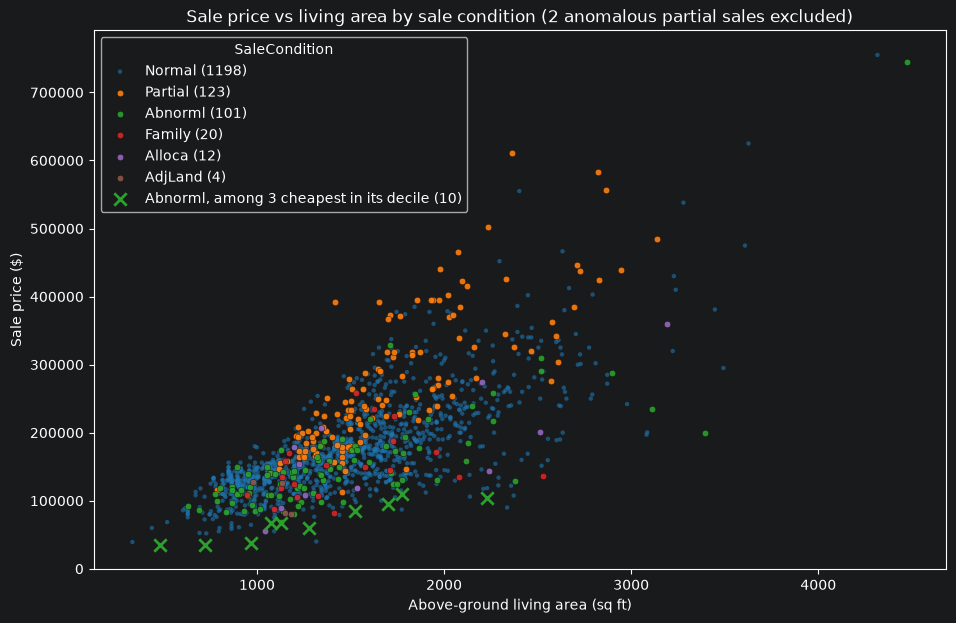

Cheapest-in-group houses: 100, of which Abnorml (stored as anomalies): 17


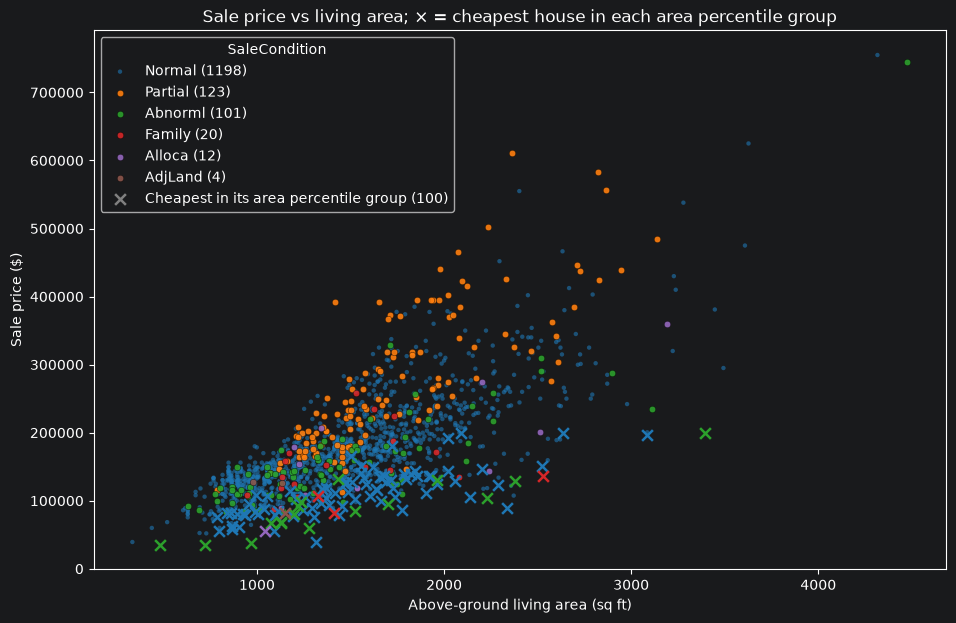

,Id,GrLivArea,SalePrice,AreaGroup,Neighborhood,SaleType,YrSold
88,89,1526,85000,57,IDOTRR,ConLD,2009
91,92,1235,98600,33,NAmes,WD,2006
198,199,2229,104000,92,OldTown,WD,2009
398,399,1077,67000,21,IDOTRR,WD,2007
410,411,1276,60000,36,Edwards,COD,2009
431,432,1198,79900,30,OldTown,ConLD,2008
495,496,720,34900,2,IDOTRR,WD,2009
635,636,3395,200000,100,SWISU,WD,2007
666,667,2380,129000,95,NAmes,WD,2007
740,741,1432,132000,48,OldTown,WD,2007


In [12]:
anomalous = ((train["SaleCondition"] == "Partial")
             & (train["GrLivArea"] > 4000)
             & (train["SalePrice"] < 300_000))
print("Excluded:", train.loc[anomalous, "Id"].tolist())
clean = train[~anomalous]

order = ["Normal", "Partial", "Abnorml", "Family", "Alloca", "AdjLand"]
colours = dict(zip(order, plt.cm.tab10.colors))

fig, ax = plt.subplots(figsize=(11, 7))
for cond in order:
    g = clean[clean["SaleCondition"] == cond]
    ax.scatter(g["GrLivArea"], g["SalePrice"], color=colours[cond],
               s=10 if cond == "Normal" else 22, alpha=0.6 if cond == "Normal" else 0.9,
               edgecolor="none" if cond == "Normal" else "black", linewidth=0.3,
               label=f"{cond} ({len(g)})", zorder=1 if cond == "Normal" else 2)

ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Sale price ($)")
ax.set_title("Sale price vs living area by sale condition (2 mistaken partial sales excluded)")
ax.legend(title="SaleCondition", loc="upper left")
plt.show()
counts = clean["SaleCondition"].value_counts().reindex(order)

fig, ax = plt.subplots(figsize=(8, 8))
wedges, _, autotexts = ax.pie(
    counts, colors=[colours[c] for c in order], startangle=90, counterclock=False,
    autopct=lambda p: f"{p:.1f}%" if p >= 3 else "",
    pctdistance=0.75, wedgeprops={"edgecolor": "white", "linewidth": 1})
ax.legend(wedges, [f"{c} ({n}, {n / counts.sum():.1%})" for c, n in counts.items()],
          title="SaleCondition", loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("Houses by sale condition (2 anomalous partial sales excluded)")
plt.show()

import matplotlib.colors as mcolors

def light(c, amount=0.3):
    """Blend a colour with white so black text stays readable on it."""
    rgb = np.array(mcolors.to_rgb(c))
    return mcolors.to_hex(rgb + (1 - rgb) * amount)

cell_colour = {cond: light(colours[cond]) for cond in order}

d = clean.copy()
d["Decile"] = pd.qcut(d["GrLivArea"], 10, labels=range(1, 11))
ranges = d.groupby("Decile", observed=True)["GrLivArea"].agg(["min", "max"])

text, cond = {}, {}
for dec, g in d.groupby("Decile", observed=True):
    cheapest = g.nsmallest(4, "SalePrice")
    row_label = f"D{dec}: {ranges.loc[dec, 'min']:,}–{ranges.loc[dec, 'max']:,} sq ft"
    text[row_label] = [f"${p:,.0f} · {a:,} sq ft · Id {i}"
                       for p, a, i in zip(cheapest["SalePrice"], cheapest["GrLivArea"], cheapest["Id"])]
    cond[row_label] = cheapest["SaleCondition"].tolist()

cols = ["Cheapest", "2nd", "3rd", "4th"]
text_df = pd.DataFrame.from_dict(text, orient="index", columns=cols)
cond_df = pd.DataFrame.from_dict(cond, orient="index", columns=cols)

styled = text_df.style.apply(
    lambda _: cond_df.map(lambda c: f"background-color: {cell_colour[c]}; color: black"), axis=None)
display(styled)

d = clean.copy()
d["Decile"] = pd.qcut(d["GrLivArea"], 10, labels=range(1, 11))

# The 3 cheapest houses in each area decile, then the Abnorml ones among them
cheapest3 = d.groupby("Decile", observed=True, group_keys=False).apply(lambda g: g.nsmallest(3, "SalePrice"))
flag_ids = cheapest3.loc[cheapest3["SaleCondition"] == "Abnorml", "Id"]
flagged = d["Id"].isin(flag_ids)
print(f"Abnorml sales among the 3 cheapest in their decile: {flagged.sum()}")

fig, ax = plt.subplots(figsize=(11, 7))
for cond in order:
    g = d[(d["SaleCondition"] == cond) & ~flagged]
    ax.scatter(g["GrLivArea"], g["SalePrice"], color=colours[cond],
               s=10 if cond == "Normal" else 22, alpha=0.6 if cond == "Normal" else 0.9,
               edgecolor="none" if cond == "Normal" else "black", linewidth=0.3,
               label=f"{cond} ({(d['SaleCondition'] == cond).sum()})",
               zorder=1 if cond == "Normal" else 2)

f = d[flagged]
ax.scatter(f["GrLivArea"], f["SalePrice"], color=colours["Abnorml"], marker="x", s=80,
           linewidth=2, zorder=3, label=f"Abnorml, among 3 cheapest in its decile ({len(f)})")

ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Sale price ($)")
ax.set_title("Sale price vs living area by sale condition (2 anomalous partial sales excluded)")
ax.legend(title="SaleCondition", loc="upper left")
plt.show()

n_groups = 100

d = clean.copy()
# Rank first so ties in GrLivArea don't create duplicate bin edges → exactly n_groups groups
d["AreaGroup"] = pd.qcut(d["GrLivArea"].rank(method="first"), n_groups, labels=range(1, n_groups + 1))

# Cheapest house in each area group
cheapest_idx = d.groupby("AreaGroup", observed=True)["SalePrice"].idxmin()
is_cheapest = d.index.isin(cheapest_idx)

# Store the Abnorml ones among them as anomalies
anomalies = d[is_cheapest & (d["SaleCondition"] == "Abnorml")].copy()
print(f"Cheapest-in-group houses: {is_cheapest.sum()}, of which Abnorml (stored as anomalies): {len(anomalies)}")

fig, ax = plt.subplots(figsize=(11, 7))
for cond in order:
    g = d[d["SaleCondition"] == cond]
    dots, crosses = g[~g.index.isin(cheapest_idx)], g[g.index.isin(cheapest_idx)]
    ax.scatter(dots["GrLivArea"], dots["SalePrice"], color=colours[cond],
               s=10 if cond == "Normal" else 22, alpha=0.6 if cond == "Normal" else 0.9,
               edgecolor="none" if cond == "Normal" else "black", linewidth=0.3,
               label=f"{cond} ({len(g)})", zorder=1 if cond == "Normal" else 2)
    ax.scatter(crosses["GrLivArea"], crosses["SalePrice"], color=colours[cond],
               marker="x", s=60, linewidth=1.8, zorder=3)

ax.scatter([], [], color="grey", marker="x", s=60, linewidth=1.8,
           label=f"Cheapest in its area percentile group ({is_cheapest.sum()})")
ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Sale price ($)")
ax.set_title("Sale price vs living area; × = cheapest house in each area percentile group")
ax.legend(title="SaleCondition", loc="upper left")
plt.show()

anomalies[["Id", "GrLivArea", "SalePrice", "AreaGroup", "Neighborhood", "SaleType", "YrSold"]]


In [ ]:

The table splits the houses into deciles, according to area, and then shows the 4 cheapest properties within each area decile. Abnorml sales are the cheapest sale within 4 out of 10 of the deciles. At least one of the three cheapest sales is an Abnorml sale, for 8 out of 10 of the deciles. This is despite making up less than 7% of sales.

When we look at the graph, the vast majority of Abnorml sales have normal sales prices for the houses area. And it can be intuited that Abnorml sales, such as foreclosures, are likely to be older houses, skewing the price down slightly, explaining the slightly lower values of the vast majority of the sales. But this does not account for the unusually low values, whose distance from the rest of the cluster indicates that Abnorml sales are not anomalous in general, but some extreme cases are.

The Abnorml Sales which feauture in the cheapest 3 houses of their area decile are shown as crosses in the last graph.


In [10]:
clean = clean.copy()
clean["Age"] = clean["YrSold"] - clean["YearBuilt"]

summary = (clean.groupby("SaleCondition")["Age"]
                .agg(houses="count", median_age="median")
                .reindex(order))
print(summary)

partial_share = (clean["SaleCondition"] == "Partial").mean()

               houses  median_age
SaleCondition                    
Normal           1198        37.0
Partial           123         1.0
Abnorml           101        46.0
Family             20        39.0
Alloca             12        34.5
AdjLand             4        60.0
